### aim: 

### date: 

In [1]:
import xarray

In [3]:
import xarray as xr

fw  = "/gpfs/data/greenocean/shared/ezs08vyu/FW_files_AnnaK/"
r5  = "/gpfs/data/greenocean/software/resources/NEMO5/"
mm2 = "/gpfs/home/mep22dku/scratch/AMOC-eco/NEMO5/masks/meshmask_v5.nc"

# ORCA1
o1_dai  = xr.open_dataset(fw + "runoff.daitren.clim.10FEB2011.nc", decode_times=False)
o1_ro1m = xr.open_dataset(fw + "runoff_1m_nomask.nc",              decode_times=False)
o1_mesh = xr.open_dataset(fw + "UKESM_mesh_mask.nc",               decode_times=False)

# ORCA2
#o2_river = xr.open_dataset(r5 + "river.v5.nc",             decode_times=False)  # file the model points to
o2_core  = xr.open_dataset(r5 + "runoff_core_monthly.nc",  decode_times=False)  # candidate alternative
o2_mesh  = xr.open_dataset(mm2,                            decode_times=False)

for name, d in [("o1_dai", o1_dai), ("o1_ro1m", o1_ro1m), ("o1_mesh", o1_mesh),
                ("o2_river", o2_river), ("o2_core", o2_core), ("o2_mesh", o2_mesh)]:
    print(f"\n=== {name} ===")
    print(dict(d.sizes))
    for v in d.data_vars:
        print(f"  {v}: {d[v].dims}, units={d[v].attrs.get('units', '')}")


=== o1_dai ===
{'Time': 12, 'ni': 360, 'nj': 180, 'nv': 4}
  xc: ('nj', 'ni'), units=degrees
  yc: ('nj', 'ni'), units=degrees
  xv: ('nv', 'nj', 'ni'), units=degrees
  yv: ('nv', 'nj', 'ni'), units=degrees
  mask: ('nj', 'ni'), units=unitless
  area: ('nj', 'ni'), units=square meters
  runoff: ('Time', 'nj', 'ni'), units=kg/s/m^2
  rEarth: (), units=meters

=== o1_ro1m ===
{'time': 12, 'xc': 362, 'yc': 332}
  nav_lat: ('yc', 'xc'), units=Degrees north
  nav_lon: ('yc', 'xc'), units=Degrees east
  socoeff: ('yc', 'xc'), units= 
  sofwfisf: ('time', 'yc', 'xc'), units=kg/m2/s
  sorunoff: ('time', 'yc', 'xc'), units=kg/m2/s
  sozisfmax: ('time', 'yc', 'xc'), units= 
  sozisfmin: ('time', 'yc', 'xc'), units= 

=== o1_mesh ===
{'nav_lev': 75, 'time_counter': 1, 'x': 362, 'y': 332}
  nav_lon: ('y', 'x'), units=
  nav_lat: ('y', 'x'), units=
  jpiglo: (), units=
  jpjglo: (), units=
  jpkglo: (), units=
  jperio: (), units=
  ln_zco: (), units=
  ln_zps: (), units=
  ln_sco: (), units=
  ln

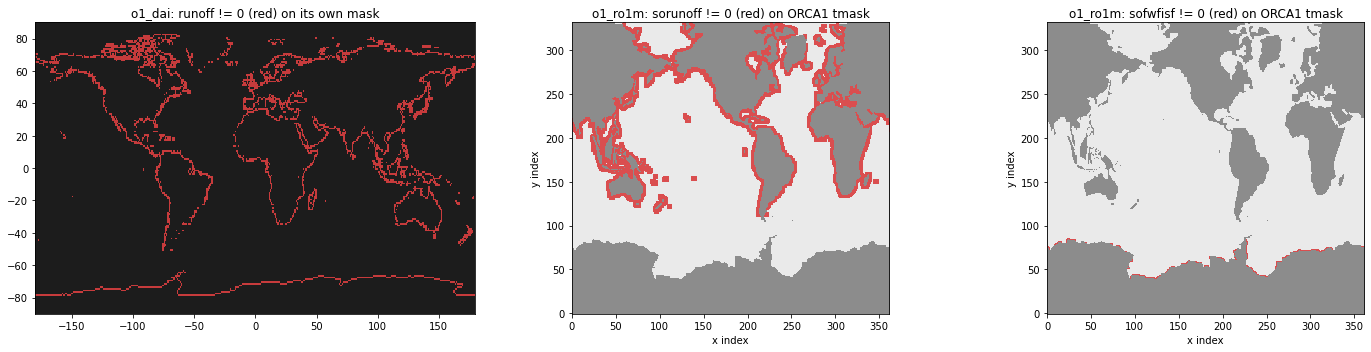

dai mask values: [1]
dai  cells with data: 3982
ro1m sorunoff cells with data: 11859 | of which on tmask land: 651616473
ro1m sofwfisf cells with data: 356


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# --- "where is there data": any non-zero, non-NaN value at any month ---
dai_has = (o1_dai["runoff"].fillna(0) != 0).any("Time")
ro_has  = (o1_ro1m["sorunoff"].fillna(0) != 0).any("time")
isf_has = (o1_ro1m["sofwfisf"].fillna(0) != 0).any("time")   # ice-shelf freshwater, same grid

# --- land/ocean backgrounds ---
tmask_sfc = o1_mesh["tmask"].isel(time_counter=0, nav_lev=0)   # ORCA1, surface level: 1 = ocean, 0 = land
dai_mask  = o1_dai["mask"]                                     # dai's own mask (check its convention below)

land_ocean = ListedColormap(["0.55", "0.92"])   # land grey, ocean light
data_cmap  = ListedColormap(["none", "tab:red"])

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# 1) o1_dai on its own regular lon/lat grid
ax = axs[0]
ax.pcolormesh(o1_dai["xc"], o1_dai["yc"], dai_mask, cmap=land_ocean, shading="auto")
ax.pcolormesh(o1_dai["xc"], o1_dai["yc"], dai_has.astype(int), cmap=data_cmap, shading="auto", alpha=0.8)
ax.set_title("o1_dai: runoff != 0 (red) on its own mask")

# 2/3) o1_ro1m on the ORCA1 grid, plotted in index space (no projection, no wraparound problems)
for ax, has, name in [(axs[1], ro_has, "sorunoff"), (axs[2], isf_has, "sofwfisf")]:
    ax.imshow(tmask_sfc, origin="lower", cmap=land_ocean, interpolation="nearest")
    ax.imshow(has.astype(int), origin="lower", cmap=data_cmap, interpolation="nearest", alpha=0.8)
    ax.set_title(f"o1_ro1m: {name} != 0 (red) on ORCA1 tmask")
    ax.set_xlabel("x index"); ax.set_ylabel("y index")

plt.tight_layout()
plt.show()

# --- quick counts ---
print("dai mask values:", np.unique(dai_mask))
print("dai  cells with data:", int(dai_has.sum()))
print("ro1m sorunoff cells with data:", int(ro_has.sum()),
      "| of which on tmask land:", int((ro_has & (tmask_sfc == 0)).sum()))
print("ro1m sofwfisf cells with data:", int(isf_has.sum()))

ORCA1 sorunoff cells with data: 11859 | of which on tmask land: 19


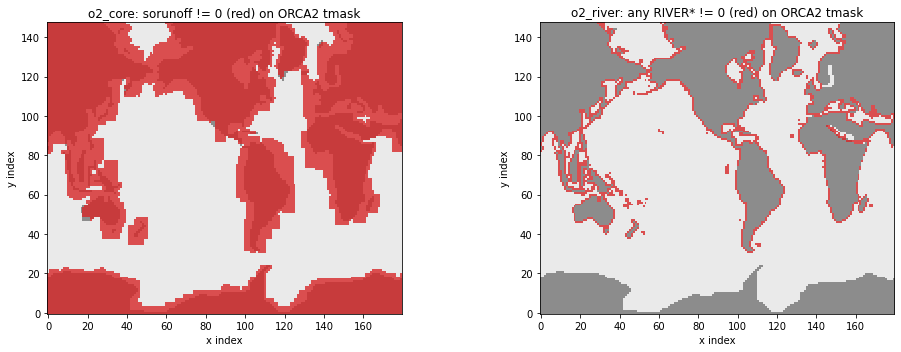

ORCA2 sorunoff cells with data: 14824 | of which on tmask land: 10175
ORCA2 BGC river cells with data: 1659 | of which on tmask land: 10
ORCA2 cells with runoff but no BGC river: 13358 | BGC river but no runoff: 193


In [6]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

land_ocean = ListedColormap(["0.55", "0.92"])   # land grey, ocean light
data_cmap  = ListedColormap(["none", "tab:red"])

# --- corrected ORCA1 count (numpy, so no dim broadcasting) ---
ro_has_np  = (o1_ro1m["sorunoff"].fillna(0) != 0).any("time").values
tmask1_sfc = o1_mesh["tmask"].isel(time_counter=0, nav_lev=0).values
print("ORCA1 sorunoff cells with data:", int(ro_has_np.sum()),
      "| of which on tmask land:", int((ro_has_np & (tmask1_sfc == 0)).sum()))

# --- ORCA2: runoff (o2_core) and BGC river inputs (o2_river) on the o2 tmask ---
tmask2_sfc = o2_mesh["tmask"].isel(deptht=0).values           # 1 = ocean, 0 = land

core_has = (o2_core["sorunoff"].fillna(0) != 0).any("time_counter").values

bgc_vars = [v for v in o2_river.data_vars if v.startswith("RIVER")]
bgc_has  = xr.concat([(o2_river[v].fillna(0) != 0) for v in bgc_vars], "v") \
             .any("v").isel(time_counter=0).values            # any of the 7 BGC fields non-zero

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, has, title in [(axs[0], core_has, "o2_core: sorunoff != 0 (red) on ORCA2 tmask"),
                       (axs[1], bgc_has,  "o2_river: any RIVER* != 0 (red) on ORCA2 tmask")]:
    ax.imshow(tmask2_sfc, origin="lower", cmap=land_ocean, interpolation="nearest")
    ax.imshow(has.astype(int), origin="lower", cmap=data_cmap, interpolation="nearest", alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel("x index"); ax.set_ylabel("y index")
plt.tight_layout()
plt.show()

print("ORCA2 sorunoff cells with data:", int(core_has.sum()),
      "| of which on tmask land:", int((core_has & (tmask2_sfc == 0)).sum()))
print("ORCA2 BGC river cells with data:", int(bgc_has.sum()),
      "| of which on tmask land:", int((bgc_has & (tmask2_sfc == 0)).sum()))
print("ORCA2 cells with runoff but no BGC river:", int((core_has & ~bgc_has).sum()),
      "| BGC river but no runoff:", int((bgc_has & ~core_has).sum()))

## assorted snippets

#### notebook footer

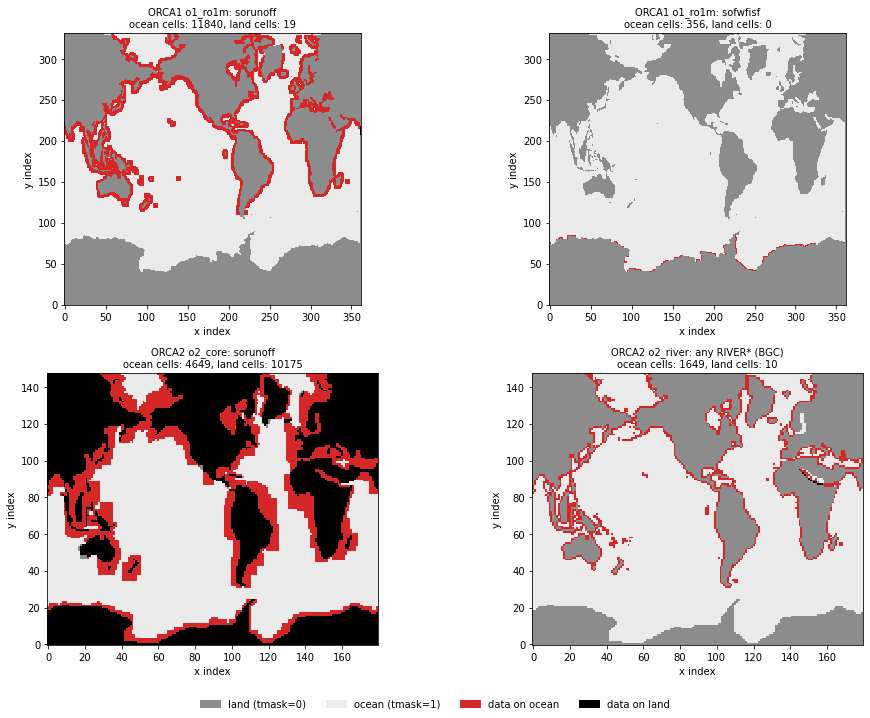

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def has_data(da, tdim):
    """True where the field is non-zero, non-NaN at any time step. Returns a plain numpy array."""
    return (da.fillna(0) != 0).any(tdim).values

# --- ORCA1 (362 x 332) ---
t1 = o1_mesh["tmask"].isel(time_counter=0, nav_lev=0).values
o1_panels = [
    ("o1_ro1m: sorunoff",  has_data(o1_ro1m["sorunoff"], "time")),
    ("o1_ro1m: sofwfisf",  has_data(o1_ro1m["sofwfisf"], "time")),
]

# --- ORCA2 (180 x 148) ---
t2 = o2_mesh["tmask"].isel(deptht=0).values
bgc_vars = [v for v in o2_river.data_vars if v.startswith("RIVER")]
bgc_has = np.any([(o2_river[v].isel(time_counter=0).fillna(0) != 0).values for v in bgc_vars], axis=0)
o2_panels = [
    ("o2_core: sorunoff",           has_data(o2_core["sorunoff"], "time_counter")),
    ("o2_river: any RIVER* (BGC)",  bgc_has),
]

# --- plot: 0 = land, 1 = ocean, 2 = data on ocean, 3 = data on land ---
cmap = ListedColormap(["0.55", "0.92", "tab:red", "black"])

def classify(tmask, has):
    out = np.where(tmask > 0, 1, 0)
    out = np.where(has & (tmask > 0), 2, out)
    out = np.where(has & (tmask == 0), 3, out)
    return out

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for row, (tmask, panels, grid) in enumerate([(t1, o1_panels, "ORCA1"), (t2, o2_panels, "ORCA2")]):
    for col, (title, has) in enumerate(panels):
        ax = axs[row, col]
        ax.imshow(classify(tmask, has), origin="lower", cmap=cmap, vmin=0, vmax=3,
                  interpolation="nearest", aspect="equal")
        n_ocean = int((has & (tmask > 0)).sum()); n_land = int((has & (tmask == 0)).sum())
        ax.set_title(f"{grid} {title}\nocean cells: {n_ocean}, land cells: {n_land}", fontsize=10)
        ax.set_xlabel("x index"); ax.set_ylabel("y index")

# shared legend
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="0.55", label="land (tmask=0)"),
                    Patch(color="0.92", label="ocean (tmask=1)"),
                    Patch(color="tab:red", label="data on ocean"),
                    Patch(color="black", label="data on land")],
           loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

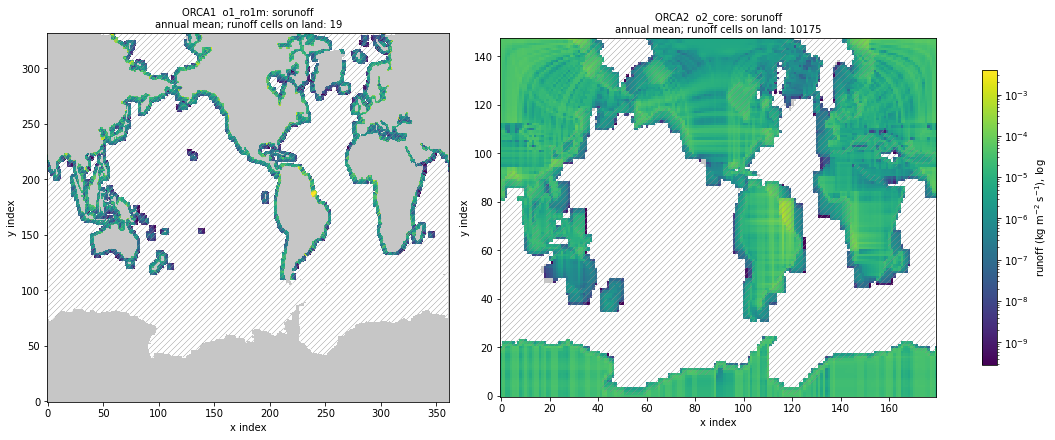

ORCA1: total runoff = 1.145 Sv
ORCA2: total runoff = 2.996 Sv


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

LOG   = True      # toggle: True = log colour scale, False = linear
MONTH = None      # None = annual mean; or 0..11 for a single month
plt.rcParams["hatch.linewidth"] = 0.4
plt.rcParams["hatch.color"] = "0.55"

def runoff_field(da, tdim):
    da = da.isel({tdim: MONTH}) if MONTH is not None else da.mean(tdim)
    a = da.values.astype(float)
    a[a == 0] = np.nan          # zeros -> transparent (essential for log scale)
    return a

t1 = o1_mesh["tmask"].isel(time_counter=0, nav_lev=0).values
t2 = o2_mesh["tmask"].isel(deptht=0).values
r1 = runoff_field(o1_ro1m["sorunoff"], "time")
r2 = runoff_field(o2_core["sorunoff"], "time_counter")

# shared colour limits so the two grids are directly comparable
allv = np.concatenate([r1[np.isfinite(r1)], r2[np.isfinite(r2)]])
allv = allv[allv > 0] if LOG else allv
vmin, vmax = np.nanpercentile(allv, 0.5), allv.max()
norm = LogNorm(vmin=vmin, vmax=vmax) if LOG else Normalize(vmin=0, vmax=vmax)

fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, tmask, r, title in [(axs[0], t1, r1, "ORCA1  o1_ro1m: sorunoff"),
                            (axs[1], t2, r2, "ORCA2  o2_core: sorunoff")]:
    ax.imshow(np.where(tmask == 0, 1.0, np.nan), origin="lower", cmap="Greys",
              vmin=0, vmax=3, interpolation="nearest")                      # land = grey
    im = ax.imshow(r, origin="lower", cmap="viridis", norm=norm, interpolation="nearest")
    ax.contourf(tmask, levels=[0.5, 1.5], colors="none", hatches=["////"])  # ocean = hatched
    n_land = int(((tmask == 0) & np.isfinite(r)).sum())
    ax.set_title(f"{title}\n{'annual mean' if MONTH is None else f'month {MONTH}'}; "
                 f"runoff cells on land: {n_land}", fontsize=10)
    ax.set_xlabel("x index"); ax.set_ylabel("y index")
fig.colorbar(im, ax=axs, shrink=0.8, label="runoff (kg m$^{-2}$ s$^{-1}$)" + (", log" if LOG else ""))
plt.show()

# sanity check: global total in Sv (1 Sv = 1e9 kg/s), using each mesh's cell area
for name, r, mesh in [("ORCA1", r1, o1_mesh), ("ORCA2", r2, o2_mesh)]:
    area = (mesh["e1t"] * mesh["e2t"]).squeeze().values
    print(f"{name}: total runoff = {np.nansum(r * area) / 1e9:.3f} Sv")

#### tylist

/gpfs/home/mep22dku/.conda/envs/swamp2/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in multiply
  import sys


ORCA1: ocean cells 1.145 Sv | land cells nan Sv | total nan Sv
ORCA2: ocean cells 1.290 Sv | land cells 1.706 Sv | total 2.996 Sv
ORCA2 ocean cells with runoff: 4649 | land cells with runoff: 10175


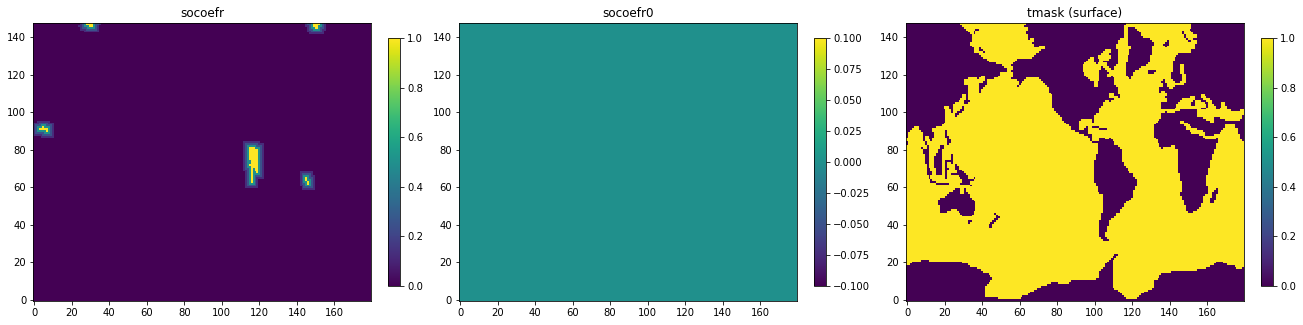

socoefr unique: [0.    0.125 0.25  0.5   1.   ]
socoefr0 unique: [0.]


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ---- ocean vs land split of the global total (Sv) ----
def split_total(r, tmask, mesh, name):
    area = (mesh["e1t"] * mesh["e2t"]).squeeze().values
    flux = np.nan_to_num(r) * area / 1e9          # Sv per cell
    oce  = tmask > 0
    print(f"{name}: ocean cells {flux[oce].sum():.3f} Sv | land cells {flux[~oce].sum():.3f} Sv "
          f"| total {flux.sum():.3f} Sv")

split_total(r1, t1, o1_mesh, "ORCA1")
split_total(r2, t2, o2_mesh, "ORCA2")

# ---- how many ORCA2 ocean cells carry runoff at all? ----
print("ORCA2 ocean cells with runoff:", int((np.isfinite(r2) & (t2 > 0)).sum()),
      "| land cells with runoff:", int((np.isfinite(r2) & (t2 == 0)).sum()))

# ---- socoefr / socoefr0 vs tmask ----
fig, axs = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, a, title in [(axs[0], o2_core["socoefr"].values,  "socoefr"),
                     (axs[1], o2_core["socoefr0"].values, "socoefr0"),
                     (axs[2], t2,                          "tmask (surface)")]:
    im = ax.imshow(a, origin="lower", interpolation="nearest")
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
print("socoefr unique:", np.unique(o2_core["socoefr"].values)[:10])
print("socoefr0 unique:", np.unique(o2_core["socoefr0"].values)[:10])

In [13]:
import numpy as np
lat1 = o1_mesh["gphit"].squeeze().values
lat2 = o2_mesh["gphit"].squeeze().values

def monthly_flux_sv(da, tdim, mesh, tmask):
    area = np.nan_to_num((mesh["e1t"] * mesh["e2t"]).squeeze().values)
    a = np.nan_to_num(da.values.astype(float)) * area * (tmask > 0) / 1e9   # Sv per cell, ocean only
    return a

m1 = monthly_flux_sv(o1_ro1m["sorunoff"], "time", o1_mesh, t1)          # (12, y, x)
m2 = monthly_flux_sv(o2_core["sorunoff"], "time_counter", o2_mesh, t2)

print("monthly total (Sv)")
print("  month  ORCA1  ORCA2")
for m in range(12):
    print(f"  {m+1:>5}  {m1[m].sum():.3f}  {m2[m].sum():.3f}")

print("\nannual-mean total by latitude band (Sv)")
for lo, hi in [(-90, -60), (-60, -30), (-30, 0), (0, 30), (30, 60), (60, 90)]:
    b1 = (lat1 >= lo) & (lat1 < hi); b2 = (lat2 >= lo) & (lat2 < hi)
    print(f"  {lo:>4}..{hi:<3}  ORCA1 {m1.mean(0)[b1].sum():.3f}  ORCA2 {m2.mean(0)[b2].sum():.3f}")

monthly total (Sv)
  month  ORCA1  ORCA2
      1  0.848  1.290
      2  0.899  1.290
      3  0.955  1.290
      4  1.041  1.290
      5  1.299  1.290
      6  1.671  1.290
      7  1.501  1.290
      8  1.421  1.290
      9  1.296  1.290
     10  1.086  1.290
     11  0.891  1.290
     12  0.838  1.290

annual-mean total by latitude band (Sv)
   -90..-60  ORCA1 0.000  ORCA2 0.053
   -60..-30  ORCA1 0.049  ORCA2 0.059
   -30..0    ORCA1 0.172  ORCA2 0.223
     0..30   ORCA1 0.527  ORCA2 0.590
    30..60   ORCA1 0.242  ORCA2 0.225
    60..90   ORCA1 0.155  ORCA2 0.139


In [12]:
import numpy as np, xarray as xr

p = "/gpfs/data/greenocean/software/runs/NEMO5/TOM12_TJ_GBA3/ORCA2_1m_20250101_20251231_grid_T.nc"
g = xr.open_dataset(p, decode_times=False)
print(dict(g.sizes))
print([v for v in g.data_vars])

# pick a surface field: tos if present, else level 0 of votemper
if "tos" in g:
    sfc = g["tos"]
else:
    sfc = g["votemper"].isel(deptht=0)
sfc0 = sfc.isel(time_counter=0).squeeze().values
print("surface field shape:", sfc0.shape, "| mesh tmask shape:", t2.shape)

ocean_nan  = np.isfinite(sfc0)            # works if land is stored as fill value -> NaN
ocean_zero = np.isfinite(sfc0) & (sfc0 != 0)   # works if land is stored as 0 (also drops exact-0 ocean points)

print("NaN cells (land if masked):", int((~np.isfinite(sfc0)).sum()),
      "| zero cells:", int((sfc0 == 0).sum()),
      "| mesh land cells:", int((t2 == 0).sum()))

for name, oc in [("NaN-based", ocean_nan), ("zero-based", ocean_zero)]:
    print(f"{name}: cells where run ocean != meshmask_v5 tmask:", int((oc != (t2 > 0)).sum()))

{'axis_nbounds': 2, 'deptht': 31, 'grid_T_3D_inner': 31, 'time_counter': 12, 'x_grid_T': 180, 'x_grid_T_2D_inner': 180, 'x_grid_T_3D_inner': 180, 'y_grid_T': 148, 'y_grid_T_2D_inner': 148, 'y_grid_T_3D_inner': 148}
['grid_T_3D_inner_bounds', 'deptht_bounds', 'time_centered_bounds', 'time_counter_bounds', 'e3t', 'votemper', 'vosaline', 'tos', 'sos', 'zos', 'mldr10_1', 'mldr0_3', 'tohfls']
surface field shape: (148, 180) | mesh tmask shape: (148, 180)
NaN cells (land if masked): 1008 | zero cells: 9199 | mesh land cells: 10207
NaN-based: cells where run ocean != meshmask_v5 tmask: 9199
zero-based: cells where run ocean != meshmask_v5 tmask: 0


In [14]:
a = o2_core["sorunoff"].values
print("max range across months, any cell:", np.nanmax(np.nanmax(a, 0) - np.nanmin(a, 0)))
print("cells that vary at all:", int((np.nanmax(a, 0) != np.nanmin(a, 0)).sum()))

max range across months, any cell: 0.0
cells that vary at all: 0


In [15]:
   f_isf = monthly_flux_sv(o1_ro1m["sofwfisf"], "time", o1_mesh, t1)
   print("ORCA1 sofwfisf annual mean (Sv):", f_isf.mean(0).sum())
   print("  south of 60S:", f_isf.mean(0)[lat1 < -60].sum())

ORCA1 sofwfisf annual mean (Sv): 0.03954211062454956
  south of 60S: 0.03954211062454956
